# H-N00 ~ H-N70 전체 결과 비교

8개 실험의 best-composite 기반 full-volume validation을 동일 기준으로 집계합니다.

- 주 비교: **GT 양성 case macro 평균** (음성 Dice의 NaN/0 왜곡 방지)
- 부피: GT NIfTI 실제 spacing × `n_ref`
- 구간: `<1`, `1–5`, `5–20`, `≥20 mL`
- detection: `TP > 0`
- H-N40은 BHSD-only라 검증 구성이 다르므로 출처별/공통-case 비교를 함께 봅니다.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

ROOT=Path("/home/stu03/workspace/model")
DATA_ROOT=Path("/home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet")
CONFIG_ROOT=ROOT/"configs/experiments/hemorrhage"; RESULTS_ROOT=ROOT/"runs/nnunet"
OUTPUT_DIR=ROOT/"runs/comparisons/H-N00_H-N70_full_results"; OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
EXPERIMENTS=["H-N00","H-N10","H-N20","H-N30","H-N40","H-N50","H-N60","H-N70"]
SIZE_ORDER=["<1 mL","1–5 mL","5–20 mL","≥20 mL"]
plt.rcParams.update({"figure.figsize":(12,5),"axes.grid":True,"grid.alpha":.2})

## 1. 설정과 결과 파일 점검

In [2]:
registry={}; status=[]
for name in EXPERIMENTS:
    cfg=yaml.safe_load((CONFIG_ROOT/f"{name}.yaml").read_text(encoding="utf-8")); e,p=cfg["experiment"],cfg["plans"]
    dataset=f"Dataset{int(e['dataset_id']):03d}_{e.get('dataset_name','ICHBinary')}"
    fold=RESULTS_ROOT/dataset/f"nnUNetTrainerICHBaseline__{p['output_identifier']}__{e['configuration']}"/f"fold_{e['fold']}"
    registry[name]={"config":cfg,"dataset":dataset,"fold":fold,"summary":fold/"validation/summary.json"}
    status.append({"experiment":name,"dataset":dataset,"plans":p["output_identifier"],"summary":(fold/"validation/summary.json").is_file(),"checkpoint":(fold/"checkpoint_best_composite.pth").is_file()})
status_df=pd.DataFrame(status); display(status_df)
missing=status_df.loc[~status_df.summary,"experiment"].tolist()
if missing: raise FileNotFoundError(f"summary.json 없음: {missing}")

,experiment,dataset,plans,summary,checkpoint
0,H-N00,Dataset001_ICHBinary,ICHPlansBaselineV1,True,True
1,H-N10,Dataset001_ICHBinary,ICHPlansResEncMV1,True,True
2,H-N20,Dataset001_ICHBinary,ICHPlansResEncMAttentionV1,True,True
3,H-N30,Dataset001_ICHBinary,ICHPlansDefaultAttentionV1,True,True
4,H-N40,Dataset002_BHSDOnly,ICHPlansBHSDBaselineV1,True,True
5,H-N50,Dataset003_ICHBinary2Window,ICHPlansTwoWindowBaselineV1,True,True
6,H-N60,Dataset001_ICHBinary,ICHPlansBaselineSmallLesionV1,True,True
7,H-N70,Dataset003_ICHBinary2Window,ICHPlansTwoWindowSmallLesionV1,True,True


## 2. case별 지표와 실제 병변 부피 계산

In [3]:
def get_case(value):
    filename=str(value).replace("\\","/").split("/")[-1]
    return filename[:-7] if filename.endswith(".nii.gz") else Path(filename).stem
rows=[]
for name,info in registry.items():
    payload=json.loads(info["summary"].read_text(encoding="utf-8")); gt_root=DATA_ROOT/"nnUNet_preprocessed"/info["dataset"]/"gt_segmentations"
    for item in payload["metric_per_case"]:
        case=get_case(item["prediction_file"]); m=item["metrics"]["1"]
        tp,fp,fn=[float(m[k]) for k in ("TP","FP","FN")]; nref=float(m["n_ref"])
        spacing=nib.load(gt_root/f"{case}.nii.gz").header.get_zooms()[:3]; volume=nref*float(np.prod(spacing))/1000; positive=nref>0
        group="negative" if not positive else "<1 mL" if volume<1 else "1–5 mL" if volume<5 else "5–20 mL" if volume<20 else "≥20 mL"
        rows.append({"experiment":name,"dataset":info["dataset"],"case_id":case,"source":"PhysioNet" if case.startswith("PHYS_") else "BHSD","positive":positive,"volume_ml":volume,"volume_group":group,"dice":float(m["Dice"]),"recall":tp/(tp+fn) if tp+fn else np.nan,"precision":tp/(tp+fp) if tp+fp else np.nan,"tp":tp,"fp":fp,"fn":fn,"predicted_voxels":tp+fp,"detected":tp>0})
case_metrics=pd.DataFrame(rows); case_metrics["volume_group"]=pd.Categorical(case_metrics.volume_group,SIZE_ORDER+["negative"],ordered=True)
display(case_metrics.head()); display(case_metrics.groupby("experiment",observed=True).agg(cases=("case_id","size"),positive=("positive","sum"),physionet=("source",lambda x:(x=="PhysioNet").sum())))

,experiment,dataset,case_id,source,positive,volume_ml,volume_group,dice,recall,precision,tp,fp,fn,predicted_voxels,detected
0,H-N00,Dataset001_ICHBinary,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,True,105.491404,≥20 mL,0.882037,0.892540,0.871778,73232.0,10771.0,8817.0,84003.0,True
1,H-N00,Dataset001_ICHBinary,BHSD_ID_07365cde_ID_8e661b8f07,BHSD,True,9.549252,5–20 mL,0.882816,0.973353,0.807688,7123.0,1696.0,195.0,8819.0,True
2,H-N00,Dataset001_ICHBinary,BHSD_ID_0b10cbee_ID_f91d6a7cd2,BHSD,True,2.676365,1–5 mL,0.000000,0.000000,0.000000,0.0,490.0,2147.0,490.0,False
3,H-N00,Dataset001_ICHBinary,BHSD_ID_10c64d22_ID_4c9aad31ca,BHSD,True,120.548283,≥20 mL,0.851946,0.845465,0.858527,78405.0,12920.0,14331.0,91325.0,True
4,H-N00,Dataset001_ICHBinary,BHSD_ID_1cbe2853_ID_37afefdc7c,BHSD,True,21.587487,≥20 mL,0.906889,0.936559,0.879041,15988.0,2200.0,1083.0,18188.0,True


,cases,positive,physionet
experiment,,,
H-N00,40,35,12
H-N10,40,35,12
H-N20,40,35,12
H-N30,40,35,12
H-N40,28,28,0
H-N50,40,35,12
H-N60,40,35,12
H-N70,40,35,12


## 3. 전체 및 양성 case 성능

`all_evaluable`은 참고값이고, 공정한 주 비교는 `positive_all`입니다.

In [4]:
def summarize(part,name,scope):
    return {"experiment":name,"scope":scope,"n":len(part),"mean_dice":part.dice.mean(),"median_dice":part.dice.median(),"mean_recall":part.recall.mean(),"mean_precision":part.precision.mean(),"detection_rate":part.detected.mean() if len(part) else np.nan,"detected_cases":int(part.detected.sum()),"zero_dice_cases":int((part.dice.fillna(0)==0).sum())}
rows=[]
for name in EXPERIMENTS:
    e=case_metrics[case_metrics.experiment==name]; rows += [summarize(e[e.dice.notna()],name,"all_evaluable"),summarize(e[e.positive],name,"positive_all")]
overall_summary=pd.DataFrame(rows); positive_summary=overall_summary[overall_summary.scope=="positive_all"].reset_index(drop=True)
display(positive_summary.style.format({"mean_dice":"{:.4f}","median_dice":"{:.4f}","mean_recall":"{:.4f}","mean_precision":"{:.4f}","detection_rate":"{:.2%}"}).background_gradient(subset=["mean_dice","mean_recall","mean_precision","detection_rate"],cmap="YlGn"))

,experiment,scope,n,mean_dice,median_dice,mean_recall,mean_precision,detection_rate,detected_cases,zero_dice_cases
0,H-N00,positive_all,35,0.5946,0.6527,0.6212,0.6068,91.43%,32,3
1,H-N10,positive_all,35,0.5452,0.6547,0.5271,0.6969,85.71%,30,5
2,H-N20,positive_all,35,0.5510,0.5482,0.5705,0.6067,88.57%,31,4
3,H-N30,positive_all,35,0.5745,0.6757,0.6738,0.5294,94.29%,33,2
4,H-N40,positive_all,28,0.6097,0.5947,0.5836,0.7166,92.86%,26,2
5,H-N50,positive_all,35,0.5855,0.6985,0.6256,0.5836,91.43%,32,3
6,H-N60,positive_all,35,0.5645,0.6241,0.6223,0.5595,91.43%,32,3
7,H-N70,positive_all,35,0.5669,0.6543,0.5361,0.6996,88.57%,31,4


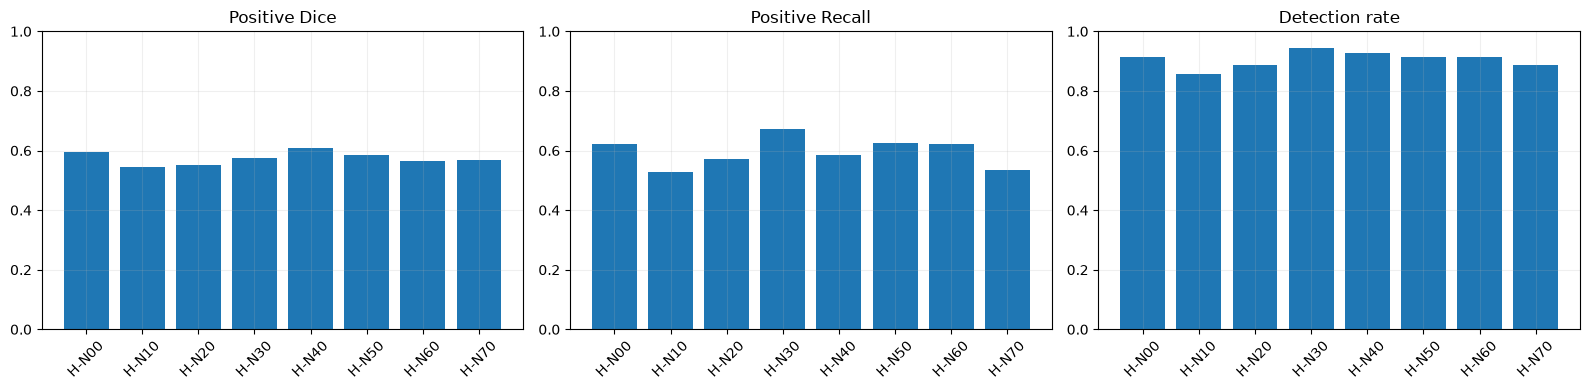

In [5]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,metric,title in zip(axes,["mean_dice","mean_recall","detection_rate"],["Positive Dice","Positive Recall","Detection rate"]):
    ax.bar(positive_summary.experiment,positive_summary[metric]); ax.set_title(title); ax.tick_params(axis="x",rotation=45); ax.set_ylim(0,1)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"overall_positive_comparison.png",dpi=170); plt.show()

## 4. BHSD / PhysioNet 출처별 비교

scope,BHSD,PhysioNet
experiment,,
H-N00,0.6247,0.4742
H-N10,0.5746,0.4276
H-N20,0.5872,0.4063
H-N30,0.6012,0.4679
H-N40,0.6097,nan
H-N50,0.6067,0.5005
H-N60,0.5924,0.4530
H-N70,0.5932,0.4615


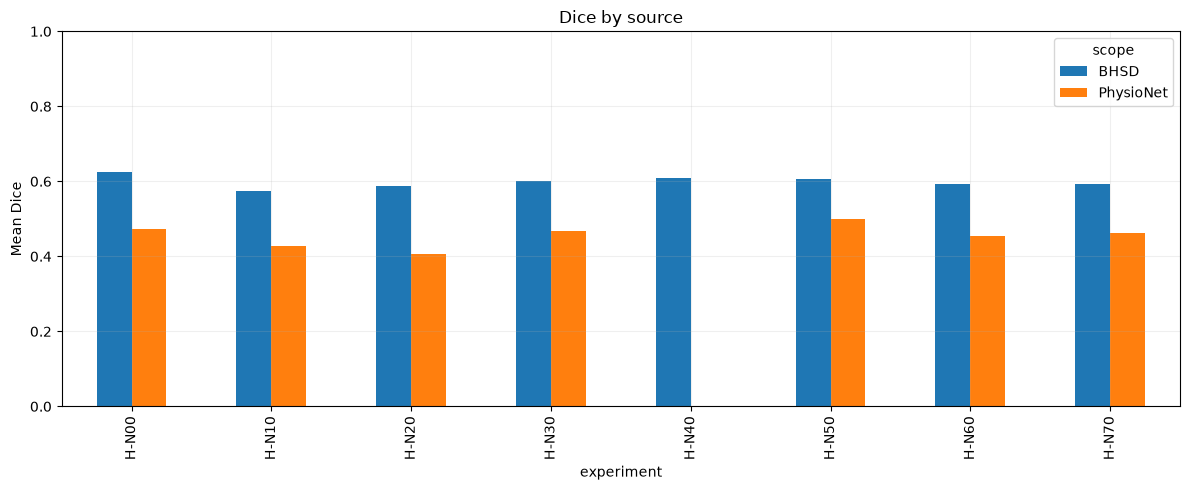

In [6]:
rows=[]
for name in EXPERIMENTS:
    pos=case_metrics[(case_metrics.experiment==name)&case_metrics.positive]
    for source in ["BHSD","PhysioNet"]:
        part=pos[pos.source==source]
        if len(part): rows.append(summarize(part,name,source))
source_summary=pd.DataFrame(rows); source_dice=source_summary.pivot(index="experiment",columns="scope",values="mean_dice").reindex(EXPERIMENTS)
display(source_dice.style.format("{:.4f}").background_gradient(cmap="YlGn"))
ax=source_dice.plot.bar(figsize=(12,5)); ax.set_ylim(0,1); ax.set_ylabel("Mean Dice"); ax.set_title("Dice by source"); plt.tight_layout(); plt.savefig(OUTPUT_DIR/"dice_by_source.png",dpi=170); plt.show()

## 5. 병변 크기별 Dice / Recall / Detection

In [7]:
rows=[]
for name in EXPERIMENTS:
    pos=case_metrics[(case_metrics.experiment==name)&case_metrics.positive]
    for group in SIZE_ORDER:
        part=pos[pos.volume_group==group]
        if len(part): rows.append(summarize(part,name,group))
size_summary=pd.DataFrame(rows)
for metric in ["mean_dice","mean_recall","detection_rate"]:
    print(metric); display(size_summary.pivot(index="experiment",columns="scope",values=metric).reindex(index=EXPERIMENTS,columns=SIZE_ORDER).style.format("{:.4f}").background_gradient(cmap="YlGn"))

mean_dice


scope,<1 mL,1–5 mL,5–20 mL,≥20 mL
experiment,,,,
H-N00,0.1254,0.4270,0.5502,0.7885
H-N10,0.2306,0.3821,0.4628,0.7270
H-N20,0.0309,0.4109,0.5012,0.7435
H-N30,0.0717,0.3536,0.5639,0.7846
H-N40,0.2579,0.5435,0.4599,0.7465
H-N50,0.0509,0.3788,0.5781,0.7927
H-N60,0.1046,0.3806,0.5150,0.7674
H-N70,0.2253,0.3913,0.5016,0.7513


mean_recall


scope,<1 mL,1–5 mL,5–20 mL,≥20 mL
experiment,,,,
H-N00,0.3563,0.5005,0.5469,0.7682
H-N10,0.2371,0.3743,0.4302,0.7064
H-N20,0.1767,0.4386,0.4768,0.7571
H-N30,0.2700,0.5592,0.6303,0.8286
H-N40,0.3138,0.5163,0.3995,0.7215
H-N50,0.2633,0.4631,0.5660,0.8046
H-N60,0.4438,0.4356,0.5246,0.7981
H-N70,0.1935,0.4130,0.4554,0.7023


detection_rate


scope,<1 mL,1–5 mL,5–20 mL,≥20 mL
experiment,,,,
H-N00,0.6667,0.7500,1.0000,1.0000
H-N10,0.3333,0.7500,0.8750,1.0000
H-N20,0.3333,0.7500,1.0000,1.0000
H-N30,0.6667,0.8750,1.0000,1.0000
H-N40,0.5000,0.8571,1.0000,1.0000
H-N50,0.6667,0.7500,1.0000,1.0000
H-N60,0.6667,0.7500,1.0000,1.0000
H-N70,0.3333,0.7500,1.0000,1.0000


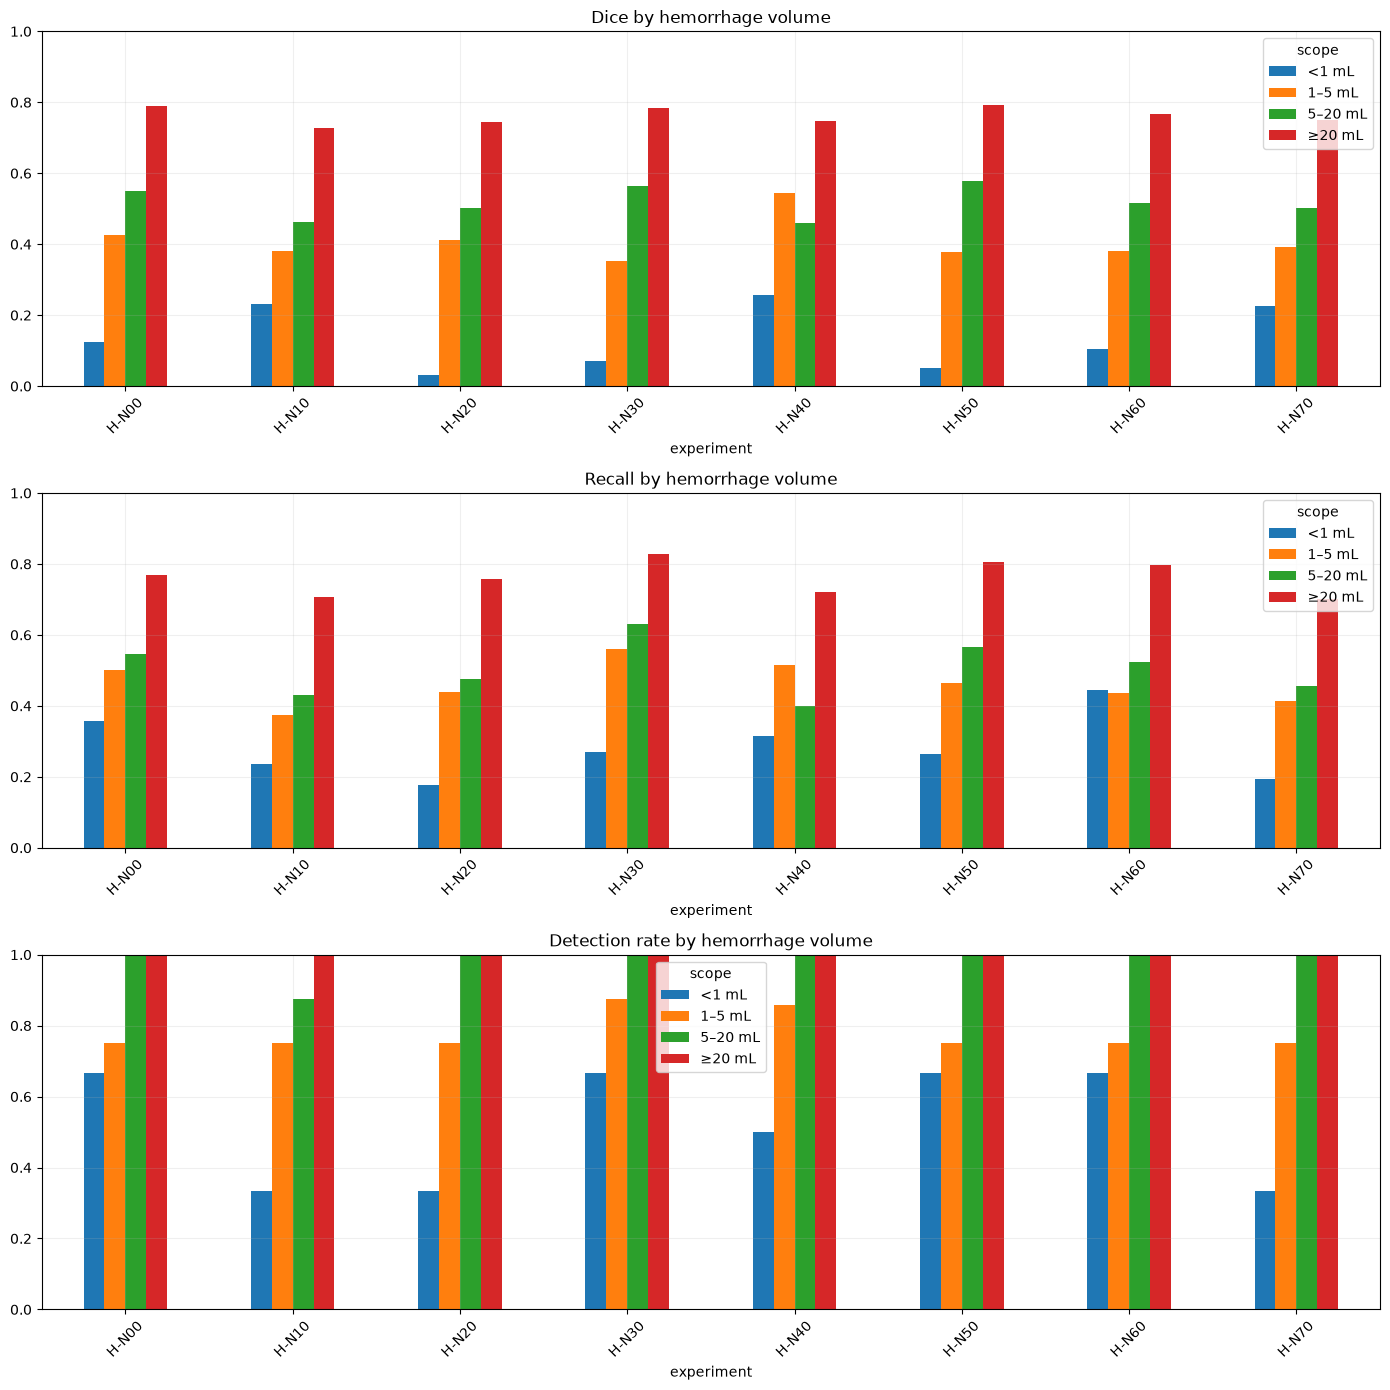

In [8]:
fig,axes=plt.subplots(3,1,figsize=(14,14))
for ax,metric,title in zip(axes,["mean_dice","mean_recall","detection_rate"],["Dice","Recall","Detection rate"]):
    size_summary.pivot(index="experiment",columns="scope",values=metric).reindex(index=EXPERIMENTS,columns=SIZE_ORDER).plot.bar(ax=ax); ax.set_ylim(0,1); ax.set_title(f"{title} by hemorrhage volume"); ax.tick_params(axis="x",rotation=45)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"metrics_by_lesion_size.png",dpi=170); plt.show()

## 6. 5 mL 미만 작은 병변 통합 비교

In [9]:
small_summary=pd.DataFrame([summarize(case_metrics[(case_metrics.experiment==name)&case_metrics.positive&(case_metrics.volume_ml<5)],name,"<5 mL") for name in EXPERIMENTS])
display(small_summary.style.format({"mean_dice":"{:.4f}","mean_recall":"{:.4f}","mean_precision":"{:.4f}","detection_rate":"{:.2%}"}).background_gradient(subset=["mean_dice","mean_recall","mean_precision","detection_rate"],cmap="YlGn"))

,experiment,scope,n,mean_dice,median_dice,mean_recall,mean_precision,detection_rate,detected_cases,zero_dice_cases
0,H-N00,<5 mL,11,0.3447,0.344262,0.4612,0.3164,72.73%,8,3
1,H-N10,<5 mL,11,0.3408,0.310464,0.3369,0.4923,63.64%,7,4
2,H-N20,<5 mL,11,0.3073,0.275568,0.3672,0.3563,63.64%,7,4
3,H-N30,<5 mL,11,0.2767,0.243650,0.4803,0.2122,81.82%,9,2
4,H-N40,<5 mL,9,0.4801,0.526295,0.4713,0.5720,77.78%,7,2
5,H-N50,<5 mL,11,0.2894,0.242396,0.4086,0.2473,72.73%,8,3
6,H-N60,<5 mL,11,0.3053,0.269285,0.4378,0.2846,72.73%,8,3
7,H-N70,<5 mL,11,0.3460,0.374525,0.3531,0.4629,63.64%,7,4


## 7. 미탐지와 핵심 PhysioNet 사례

In [10]:
missed_cases=case_metrics[case_metrics.positive&~case_metrics.detected].sort_values(["experiment","volume_ml"])
display(missed_cases[["experiment","case_id","source","volume_ml","dice","fp","fn"]])
key_phys=case_metrics[case_metrics.case_id.isin(["PHYS_58","PHYS_78","PHYS_82"])].sort_values(["case_id","experiment"])
display(key_phys[["experiment","case_id","volume_ml","dice","recall","precision","tp","fp","fn","detected"]].style.format({"volume_ml":"{:.3f}","dice":"{:.4f}","recall":"{:.4f}","precision":"{:.4f}"}))

,experiment,case_id,source,volume_ml,dice,fp,fn
34,H-N00,PHYS_58,PhysioNet,0.252899,0.0,774.0,279.0
38,H-N00,PHYS_82,PhysioNet,1.694899,0.0,192.0,2015.0
2,H-N00,BHSD_ID_0b10cbee_ID_f91d6a7cd2,BHSD,2.676365,0.0,490.0,2147.0
47,H-N10,BHSD_ID_47aa2b3a_ID_95a9953aba,BHSD,0.178717,0.0,1447.0,115.0
74,H-N10,PHYS_58,PhysioNet,0.252899,0.0,34.0,279.0
78,H-N10,PHYS_82,PhysioNet,1.694899,0.0,0.0,2015.0
42,H-N10,BHSD_ID_0b10cbee_ID_f91d6a7cd2,BHSD,2.676365,0.0,0.0,2147.0
77,H-N10,PHYS_78,PhysioNet,5.720863,0.0,4055.0,6737.0
87,H-N20,BHSD_ID_47aa2b3a_ID_95a9953aba,BHSD,0.178717,0.0,1667.0,115.0
114,H-N20,PHYS_58,PhysioNet,0.252899,0.0,206.0,279.0


,experiment,case_id,volume_ml,dice,recall,precision,tp,fp,fn,detected
34,H-N00,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,774.000000,279.000000,False
74,H-N10,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,34.000000,279.000000,False
114,H-N20,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,206.000000,279.000000,False
154,H-N30,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,1843.000000,279.000000,False
222,H-N50,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,932.000000,279.000000,False
262,H-N60,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,1629.000000,279.000000,False
302,H-N70,PHYS_58,0.253,0.0000,0.0000,0.0000,0.000000,91.000000,279.000000,False
37,H-N00,PHYS_78,5.721,0.1494,0.1280,0.1795,862.000000,3940.000000,5875.000000,True
77,H-N10,PHYS_78,5.721,0.0000,0.0000,0.0000,0.000000,4055.000000,6737.000000,False
117,H-N20,PHYS_78,5.721,0.0020,0.0016,0.0025,11.000000,4320.000000,6726.000000,True


## 8. H-N00 대비 공통 case paired 변화

두 실험 모두에 존재하는 동일한 양성 case만 비교합니다. H-N40의 다른 split도 공통 case 수를 명시합니다.

In [11]:
baseline=case_metrics[(case_metrics.experiment=="H-N00")&case_metrics.positive].set_index("case_id"); rows=[]
for name in EXPERIMENTS[1:]:
    current=case_metrics[(case_metrics.experiment==name)&case_metrics.positive].set_index("case_id"); common=baseline.index.intersection(current.index)
    delta=current.loc[common,["dice","recall","precision"]]-baseline.loc[common,["dice","recall","precision"]]
    rows.append({"experiment":name,"common_positive_cases":len(common),"mean_dice_delta":delta.dice.mean(),"median_dice_delta":delta.dice.median(),"mean_recall_delta":delta.recall.mean(),"mean_precision_delta":delta.precision.mean(),"improved_dice_cases":int((delta.dice>0).sum()),"worsened_dice_cases":int((delta.dice<0).sum())})
paired_summary=pd.DataFrame(rows); display(paired_summary.style.format({"mean_dice_delta":"{:+.4f}","median_dice_delta":"{:+.4f}","mean_recall_delta":"{:+.4f}","mean_precision_delta":"{:+.4f}"}).background_gradient(subset=["mean_dice_delta","mean_recall_delta","mean_precision_delta"],cmap="RdYlGn",vmin=-.1,vmax=.1))

,experiment,common_positive_cases,mean_dice_delta,median_dice_delta,mean_recall_delta,mean_precision_delta,improved_dice_cases,worsened_dice_cases
0,H-N10,35,-0.0493,-0.0174,-0.0940,+0.0533,8,24
1,H-N20,35,-0.0435,-0.0208,-0.0507,-0.0179,9,23
2,H-N30,35,-0.0200,-0.0148,+0.0526,-0.0774,10,23
3,H-N40,28,-0.0150,-0.0108,-0.0748,+0.0558,11,16
4,H-N50,35,-0.0091,+0.0000,+0.0045,-0.0232,17,15
5,H-N60,35,-0.0301,-0.0123,+0.0012,-0.0474,10,22
6,H-N70,35,-0.0277,-0.0140,-0.0850,+0.0749,8,24


## 9. Online patch 지표와 full-volume 지표

In [12]:
rows=[]
for name,info in registry.items():
    path=info["fold"]/"custom_metrics.json"
    if path.is_file():
        m=json.loads(path.read_text(encoding="utf-8")); full=positive_summary.set_index("experiment").loc[name]
        rows.append({"experiment":name,"online_best_dice":m.get("best_dice"),"online_best_recall":m.get("best_recall"),"online_best_composite":m.get("best_composite"),"full_positive_dice":full.mean_dice,"full_positive_recall":full.mean_recall})
online_vs_full=pd.DataFrame(rows); display(online_vs_full.style.format({column: "{:.4f}" for column in online_vs_full.columns if column != "experiment"}))

,experiment,online_best_dice,online_best_recall,online_best_composite,full_positive_dice,full_positive_recall
0,H-N00,0.8286,0.8545,0.8403,0.5946,0.6212
1,H-N10,0.8310,0.8566,0.8428,0.5452,0.5271
2,H-N20,0.8511,0.8950,0.8627,0.5510,0.5705
3,H-N30,0.8415,0.8962,0.8555,0.5745,0.6738
4,H-N40,0.8301,0.8482,0.8392,0.6097,0.5836
5,H-N50,0.8528,0.8629,0.8499,0.5855,0.6256
6,H-N60,0.8393,0.8479,0.8247,0.5645,0.6223
7,H-N70,0.8376,0.8302,0.8261,0.5669,0.5361


## 10. CSV/그림 저장 및 leaderboard

In [13]:
leaderboard=positive_summary[["experiment","n","mean_dice","mean_recall","mean_precision","detection_rate","zero_dice_cases"]].merge(small_summary[["experiment","mean_dice","mean_recall","mean_precision","detection_rate"]],on="experiment",suffixes=("_all_positive","_under_5ml")).sort_values("mean_dice_all_positive",ascending=False)
tables={"per_case_metrics.csv":case_metrics,"overall_summary.csv":overall_summary,"source_summary.csv":source_summary,"size_summary.csv":size_summary,"small_under_5ml_summary.csv":small_summary,"paired_vs_H-N00.csv":paired_summary,"online_vs_full.csv":online_vs_full,"leaderboard.csv":leaderboard,"missed_cases.csv":missed_cases}
for filename,table in tables.items(): table.to_csv(OUTPUT_DIR/filename,index=False)
print("saved:",OUTPUT_DIR)
display(leaderboard.style.format({c:"{:.4f}" for c in leaderboard.columns if c not in ["experiment","n","zero_dice_cases"]}).background_gradient(subset=["mean_dice_all_positive","mean_recall_all_positive","mean_dice_under_5ml","detection_rate_under_5ml"],cmap="YlGn"))

saved: /home/stu03/workspace/model/runs/comparisons/H-N00_H-N70_full_results


,experiment,n,mean_dice_all_positive,mean_recall_all_positive,mean_precision_all_positive,detection_rate_all_positive,zero_dice_cases,mean_dice_under_5ml,mean_recall_under_5ml,mean_precision_under_5ml,detection_rate_under_5ml
4,H-N40,28,0.6097,0.5836,0.7166,0.9286,2,0.4801,0.4713,0.5720,0.7778
0,H-N00,35,0.5946,0.6212,0.6068,0.9143,3,0.3447,0.4612,0.3164,0.7273
5,H-N50,35,0.5855,0.6256,0.5836,0.9143,3,0.2894,0.4086,0.2473,0.7273
3,H-N30,35,0.5745,0.6738,0.5294,0.9429,2,0.2767,0.4803,0.2122,0.8182
7,H-N70,35,0.5669,0.5361,0.6996,0.8857,4,0.3460,0.3531,0.4629,0.6364
6,H-N60,35,0.5645,0.6223,0.5595,0.9143,3,0.3053,0.4378,0.2846,0.7273
2,H-N20,35,0.5510,0.5705,0.6067,0.8857,4,0.3073,0.3672,0.3563,0.6364
1,H-N10,35,0.5452,0.5271,0.6969,0.8571,5,0.3408,0.3369,0.4923,0.6364


## 해석 체크리스트

1. 기본 선택 기준은 `positive_all mean_dice`입니다.
2. 작은 병변은 Dice뿐 아니라 recall, detection rate, Dice 0 사례를 같이 봅니다.
3. precision 상승과 recall 하락이 함께 나타나면 더 보수적인 예측입니다.
4. H-N40은 BHSD-only이므로 BHSD 열과 공통-case 표로 해석합니다.
5. `<1 mL`은 표본이 적으므로 반드시 개별 사례도 확인합니다.